# Unión de las bases geoespaciales por vía — Malla vial, puentes, malla peatonal, semáforos y siniestralidad

Este cuaderno une las capas geoespaciales base tomando la **vía original completa** (sin
subdividir en tramos) como unidad de análisis, y asigna cada elemento de infraestructura y de
siniestralidad a la vía más cercana mediante vecino más próximo (`sjoin_nearest`):

1. La **malla vial** recortada al perímetro POT se conserva con la longitud real de cada vía,
   sin subdividir en tramos de longitud fija.
2. Puentes y semáforos se resumen como distancia a la vía; los siniestros se asignan a la vía
   más cercana; la malla peatonal se resume como un indicador de cobertura (proporción de la
   vía con malla a ≤ 15 m).
3. El resultado es una tabla a nivel de vía: una fila = una vía (o una parte de una vía
   multiparte), con sus atributos propios, su dotación de infraestructura y su **conteo de
   siniestros peatonales**, que es la variable objetivo de este cuaderno.

**Insumos requeridos** (generados por los cuadernos previos):

| Archivo | Origen |
|---|---|
| `Data/raw/perimetrourbano (1).gpkg` | POT Decreto 555 |
| `Data/processed/malla_vial_procesada.gpkg` | `EDA_Malla_Vial_Puentes_zona_urbana.ipynb` |
| `Data/processed/puentes_procesado.gpkg` | idem |
| `Data/processed/peatonal_procesada.gpkg` | `EDA_Malla_peatonal_semaforos.ipynb` |
| `Data/processed/semaforos_procesados.gpkg` | idem |
| `Data/processed/siniestros_procesados.gpkg` | `EDA2_Siniestros_Viales_Bogota_peatones...ipynb` (sección 9) |
| `Data/raw/osb_demografia-poblacion-localidad.csv` | SDS/SaluData (convenio DANE-SDP) — población por localidad, 2005-2035 |
| `Data/raw/localidades_bogota.gpkg` | SDP — polígonos de localidades (columna `LocNombre`) |

Todo en **EPSG:3116** (MAGNA-SIRGAS / Bogotá), condición necesaria para que las distancias
estén en metros reales.


El cuaderno está organizado así:

1. Librerías y parámetros del diseño
2. Carga de insumos y estandarización de CRS
3. Vías como unidad de análisis (sin subdivisión)
4. Agregación de las capas a cada segmento (vecino más cercano)
5. Construcción del dataset final por segmento
6. Vista espacial del resultado
7. Exportación
8. Resumen metodológico

## 1. Librerías y parámetros del diseño

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 80)
plt.rcParams['figure.figsize'] = (9, 6)

# ---------------------------------------------------------------
# PARÁMETROS DEL DISEÑO METODOLÓGICO
# ---------------------------------------------------------------
CRS_PROYECTO = 3116          # MAGNA-SIRGAS / Colombia Bogotá zone (metros)
UMBRAL_RUIDO = 4             # descarta geometrías degeneradas de digitalización
UMBRAL_PEATONAL_M = 15       # distancia máxima a la que una vía se considera 'cubierta' por malla peatonal
PASO_COBERTURA_M = 5         # separación aprox. entre puntos de muestreo a lo largo de cada vía
UMBRAL_SINIESTROS_M = 30     # distancia máxima para asignar un siniestro a una vía

DIR_PROC = 'Data/processed'
os.makedirs(DIR_PROC, exist_ok=True)

print(f"Umbral peatonal: {UMBRAL_PEATONAL_M} m | Umbral siniestros: {UMBRAL_SINIESTROS_M} m")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\traitlets\config\application.py", line 1080, in launch_instance
    app.start()
  File "c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



Umbral peatonal: 15 m | Umbral siniestros: 30 m


## 2. Carga de insumos y estandarización de CRS

Se fuerza el CRS de todas las capas a `EPSG:3116` en vez de asumirlo. Un CRS mal etiquetado
(grados tratados como metros) no falla de forma visible: produce distancias sin sentido físico.

In [2]:
def cargar(ruta, nombre):
    gdf = gpd.read_file(ruta)
    if gdf.crs is None:
        raise ValueError(f"{nombre}: la capa no tiene CRS definido; no se puede asumir.")
    if gdf.crs.to_epsg() != CRS_PROYECTO:
        gdf = gdf.to_crs(epsg=CRS_PROYECTO)
    n0 = len(gdf)
    gdf = gdf[~gdf.geometry.isna() & ~gdf.geometry.is_empty].copy()
    print(f"{nombre:11s}: {n0:>8,} -> {len(gdf):>8,} (descartadas {n0-len(gdf):,} sin geometría)")
    return gdf

perimetro  = cargar("Data/raw/perimetrourbano (1).gpkg", 'perimetro')
malla      = cargar(f"{DIR_PROC}/malla_vial_procesada.gpkg", 'malla')
puentes    = cargar(f"{DIR_PROC}/puentes_procesado.gpkg", 'puentes')
peatonal   = cargar(f"{DIR_PROC}/peatonal_procesada.gpkg", 'peatonal')
semaforos  = cargar(f"{DIR_PROC}/semaforos_procesados.gpkg", 'semaforos')
siniestros = cargar(f"{DIR_PROC}/siniestros_procesados.gpkg", 'siniestros')

# El perímetro se reduce a una sola geometría disuelta: es una máscara, no una tabla.
perimetro = gpd.GeoDataFrame(geometry=[perimetro.union_all()], crs=perimetro.crs)

for nombre, capa in [('perimetro', perimetro), ('malla', malla), ('puentes', puentes),
                     ('peatonal', peatonal), ('semaforos', semaforos), ('siniestros', siniestros)]:
    print(f"{nombre:11s} -> {len(capa):>8,} filas | {capa.crs.to_epsg()} | "
          f"{sorted(capa.geom_type.unique())}")

c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column FECHA_ACTO_ADMINISTRATIVO, 2022-07-29T00:00:00.0Z, successfully parsed
  return ogr_read(


perimetro  :        6 ->        6 (descartadas 0 sin geometría)
malla      :  136,957 ->  136,957 (descartadas 0 sin geometría)
puentes    :    1,212 ->    1,212 (descartadas 0 sin geometría)
peatonal   :   46,065 ->   46,065 (descartadas 0 sin geometría)
semaforos  :    1,745 ->    1,745 (descartadas 0 sin geometría)
siniestros :   23,447 ->   21,893 (descartadas 1,554 sin geometría)
perimetro   ->        1 filas | 3116 | ['MultiPolygon']
malla       ->  136,957 filas | 3116 | ['MultiLineString']
puentes     ->    1,212 filas | 3116 | ['MultiPolygon']
peatonal    ->   46,065 filas | 3116 | ['MultiLineString']
semaforos   ->    1,745 filas | 3116 | ['Point']
siniestros  ->   21,893 filas | 3116 | ['Point']


### 2.1 Recorte al perímetro urbano

Mismo criterio para todas las capas: lo que queda fuera del POT no entra al modelo. Se hace
antes de asignar las capas para no gastar cómputo con elementos que después se descartan.

Los semáforos se filtran aparte por coordenadas imposibles (registros corruptos de fuente,
no error de CRS) — ese diagnóstico ya venía del cuaderno anterior.

In [3]:
# Semáforos: exclusión de coordenadas físicamente imposibles (fuera de cualquier
# proyección válida para Bogotá). Se separa del clip porque es un problema de calidad
# de fuente, no de delimitación urbana.
minx, miny, maxx, maxy = perimetro.total_bounds
MARGEN = 5000
corruptos = semaforos[
    (semaforos.geometry.x < minx - MARGEN) | (semaforos.geometry.x > maxx + MARGEN) |
    (semaforos.geometry.y < miny - MARGEN) | (semaforos.geometry.y > maxy + MARGEN)
]
print(f"Semáforos con coordenada corrupta excluidos: {len(corruptos)} de {len(semaforos)}")
semaforos = semaforos.drop(index=corruptos.index).copy()

# Clip al POT de todas las capas
capas = {}
for nombre, capa in [('malla', malla), ('puentes', puentes), ('peatonal', peatonal),
                     ('semaforos', semaforos), ('siniestros', siniestros)]:
    antes = len(capa)
    recortada = gpd.clip(capa, perimetro)
    capas[nombre] = recortada
    print(f"{nombre:11s}: {antes:>8,} -> {len(recortada):>8,} "
          f"({len(recortada)/antes*100:5.1f}% conservado)")
    assert len(recortada) / antes > 0.80, \
        f"{nombre}: el recorte al POT conserva solo {len(recortada)/antes*100:.1f} % — revisar CRS del perímetro"

malla, puentes, peatonal, semaforos, siniestros = (
    capas['malla'], capas['puentes'], capas['peatonal'],
    capas['semaforos'], capas['siniestros'])

Semáforos con coordenada corrupta excluidos: 1 de 1745
malla      :  136,957 ->  131,874 ( 96.3% conservado)
puentes    :    1,212 ->    1,068 ( 88.1% conservado)
peatonal   :   46,065 ->   45,964 ( 99.8% conservado)
semaforos  :    1,744 ->    1,733 ( 99.4% conservado)
siniestros :   21,893 ->   21,716 ( 99.2% conservado)


## 3. Vías como unidad de análisis (sin subdivisión)

Cada vía original se conserva **completa**, con su longitud real, en vez de subdividirse en
tramos de longitud fija: evita introducir cortes artificiales y los tramos de borde que esos
cortes generaban. La longitud de cada vía queda disponible en `long_seg_m`, y es la que hay
que tener en cuenta al comparar conteos entre vías de tamaños muy distintos — una avenida larga
va a acumular más siniestros solo por tener más metros de exposición, no necesariamente porque
sea más peligrosa.

### 3.1 Identificador de la vía madre y filtro de ruido

Se conserva `vial_id` (código original MVI) para poder identificar cada vía, y se descartan
las geometrías por debajo del umbral de ruido: no tiene sentido tratar como vía algo que no
lo es.

In [4]:
id_col = 'MVICODIGO' if 'MVICODIGO' in malla.columns else 'OBJECTID'
malla_base = malla.rename(columns={id_col: 'vial_id'}).copy()

# Variables de diseño vial que entran al modelo (Tabla 5): velocidad reglamentaria y número de
# calzadas, ya imputadas por KNN en EDA_Malla_Vial_Puentes. Son OBLIGATORIAS: si faltan en el
# insumo se detiene la ejecución en vez de descartarlas en silencio.
COLS_DISENO_VIAL = ['MVI_VELREG', 'MVINUMC']
faltantes = [c for c in COLS_DISENO_VIAL if c not in malla_base.columns]
if faltantes:
    raise ValueError(f"Faltan en malla_vial_procesada.gpkg variables obligatorias: {faltantes}")

cols_utiles = (['vial_id'] + COLS_DISENO_VIAL
               + [c for c in ['MVITIPO', 'MVISVIA'] if c in malla_base.columns] + ['geometry'])
malla_base = malla_base[cols_utiles]

# Explotar multipartes y descartar ruido de digitalización
malla_base = malla_base.explode(index_parts=False).reset_index(drop=True)
malla_base['long_m'] = malla_base.geometry.length

antes = len(malla_base)
malla_base = malla_base[malla_base['long_m'] >= UMBRAL_RUIDO].copy()
print(f"Geometrías descartadas por ruido (< {UMBRAL_RUIDO} m): {antes - len(malla_base)}")
print(f"Vías conservadas: {len(malla_base):,}")
print(f"Longitud total de red: {malla_base['long_m'].sum():,.0f} m")

Geometrías descartadas por ruido (< 4 m): 305
Vías conservadas: 131,705
Longitud total de red: 8,150,422 m


In [5]:
def segmentar_capa(gdf):
    """Cada vía original (tras explotar multipartes) se conserva como un único
    segmento, con su longitud real — ya no se subdivide en tramos de longitud fija.
    Se mantiene el nombre por compatibilidad con el resto del pipeline."""
    base = gdf.explode(index_parts=False).reset_index(drop=True)
    base = base[base.geom_type == 'LineString'].copy()

    seg = base.copy()
    seg['linea_madre_idx'] = seg.index
    seg['long_seg_m'] = seg.geometry.length
    seg = seg.reset_index(drop=True)
    seg['seg_id'] = 'S' + seg.index.astype(str).str.zfill(7)
    return seg

segmentos = segmentar_capa(malla_base)

print(f"Vías (segmentos): {len(segmentos):,}")
print(segmentos['long_seg_m'].describe().round(2))
print(f"\nLongitud total de red: {segmentos['long_seg_m'].sum():,.0f} m")

Vías (segmentos): 131,705
count    131705.00
mean         61.88
std          49.96
min           4.01
25%          31.09
50%          49.59
75%          81.02
max        2893.62
Name: long_seg_m, dtype: float64

Longitud total de red: 8,150,422 m


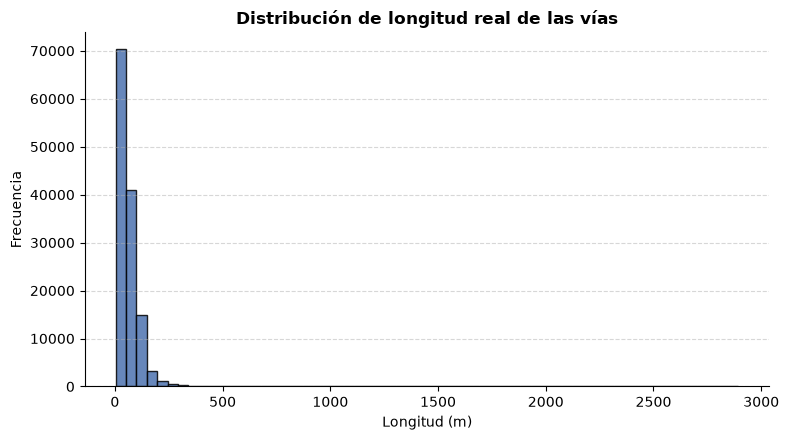

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(segmentos['long_seg_m'], bins=60, color='#4C72B0', edgecolor='black', alpha=0.85)
ax.set_title('Distribución de longitud real de las vías', fontweight='bold')
ax.set_xlabel('Longitud (m)'); ax.set_ylabel('Frecuencia')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

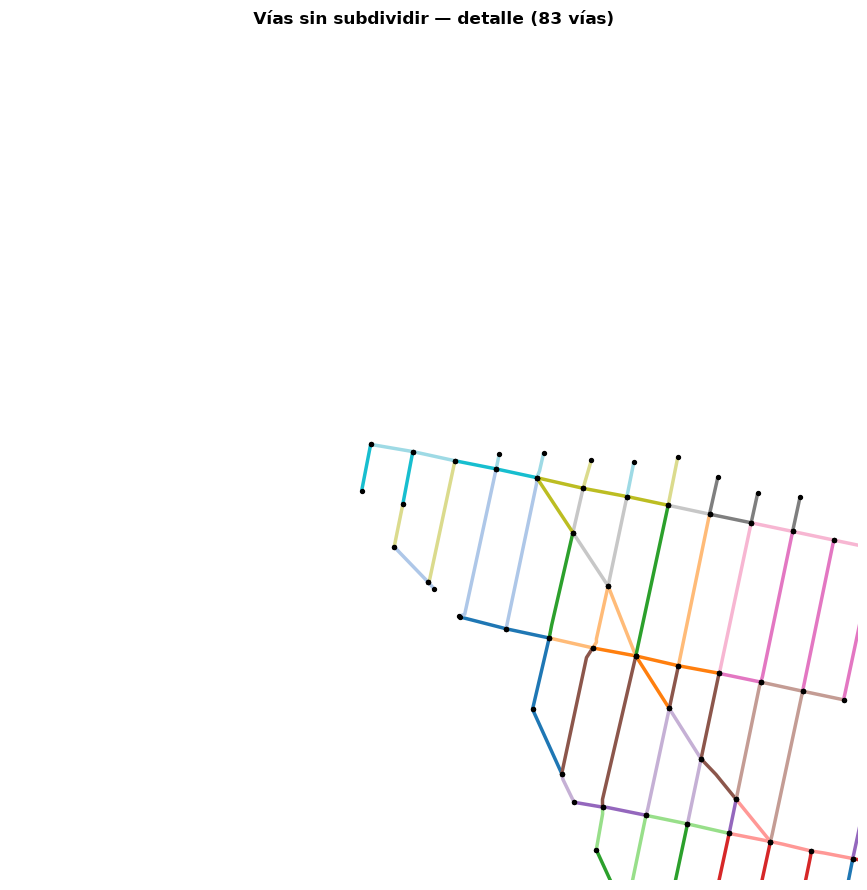

In [7]:
# Inspección visual en una ventana pequeña: cada vía en un color distinto
cx, cy = segmentos.geometry.iloc[len(segmentos)//2].centroid.coords[0]
R = 300

ventana = segmentos.cx[cx-R:cx+R, cy-R:cy+R]
fig, ax = plt.subplots(figsize=(9, 9))
ventana.plot(ax=ax, column='seg_id', cmap='tab20', linewidth=2.5, legend=False)
ventana.geometry.boundary.plot(ax=ax, color='black', markersize=8, zorder=3)
ax.set_xlim(cx-R, cx+R); ax.set_ylim(cy-R, cy+R)
ax.set_title(f'Vías sin subdividir — detalle ({len(ventana)} vías)', fontweight='bold')
ax.set_axis_off(); plt.tight_layout(); plt.show()

## 4. Agregación de las capas a cada segmento (vecino más cercano)

### 4.1 Nota metodológica: asignación por vecino más próximo

Cada elemento de las capas de
infraestructura y de siniestralidad se asigna a la vía más cercana mediante `sjoin_nearest`:

- **Puentes y semáforos** se resumen como **distancia al más cercano**, sin límite de
  distancia — la métrica en sí es la distancia, así que no hace falta descartar nada.
- **Siniestros** se **cuentan** en la vía más cercana dentro de un umbral de distancia
  (`UMBRAL_SINIESTROS_M`), para no asignarle a una vía siniestros que en realidad están lejos.
- **Malla peatonal** se resume como un **indicador de cobertura**: la proporción de la longitud
  de la vía que tiene malla peatonal a `UMBRAL_PEATONAL_M` o menos (sección 4.4). No se usa
  vecino más próximo para esta capa.




### 4.2 Puentes

Los puentes son polígonos, pero aquí se resumen como la **distancia (m) de la vía al puente
más cercano**, mediante vecino más próximo, sin límite de distancia. Una distancia de 0
significa que la vía cruza o toca físicamente un puente.

In [8]:
# SUPUESTO A VERIFICAR con IDECA/IDU: 1 = Vehicular (catálogo IDECA), 2 = Peatonal (por confirmar)
TIPO_VEHICULAR = 1
TIPO_PEATONAL  = 2   # si la verificación indica otro código, cambiar SOLO aquí

COL_ID_PUENTE = 'PueCodigo' if 'PueCodigo' in puentes.columns else puentes.columns[0]

def _dist_min_a(capa, nombre_col):
    """Distancia (m) de cada segmento al elemento más cercano de `capa`, sin límite de distancia."""
    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        capa[[COL_ID_PUENTE, 'geometry']],
        distance_col=nombre_col
    )
    # groupby.min resuelve los empates que sjoin_nearest devuelve como filas duplicadas
    return cercano.groupby('seg_id', as_index=False)[nombre_col].min()

def agregar_puentes():
    """Distancias (m) de cada vía al puente más cercano: peatonal, vehicular y de cualquier tipo."""
    puentes_peat = puentes[puentes['PueTipo'] == TIPO_PEATONAL]
    puentes_veh  = puentes[puentes['PueTipo'] == TIPO_VEHICULAR]

    res = _dist_min_a(puentes, 'dist_puente_m')
    if len(puentes_peat):
        res = res.merge(_dist_min_a(puentes_peat, 'dist_puente_peatonal_m'), on='seg_id', how='left')
    if len(puentes_veh):
        res = res.merge(_dist_min_a(puentes_veh, 'dist_puente_vehicular_m'), on='seg_id', how='left')
    return res

puentes_agg = agregar_puentes()

for col, etiqueta in [('dist_puente_m', 'cualquier puente'),
                      ('dist_puente_peatonal_m', 'puente peatonal (supuesto tipo 2)'),
                      ('dist_puente_vehicular_m', 'puente vehicular (tipo 1)')]:
    if col in puentes_agg:
        s = puentes_agg[col]
        print(f"Distancia a {etiqueta} -> media {s.mean():.1f} m | mediana {s.median():.1f} m | "
              f"vías sobre un puente (dist=0): {(s == 0).sum():,} | "
              f"vías con dato: {s.notna().sum():,} de {len(segmentos):,}")

Distancia a cualquier puente -> media 463.5 m | mediana 379.4 m | vías sobre un puente (dist=0): 3,261 | vías con dato: 131,705 de 131,705
Distancia a puente peatonal (supuesto tipo 2) -> media 573.5 m | mediana 481.8 m | vías sobre un puente (dist=0): 1,148 | vías con dato: 131,705 de 131,705
Distancia a puente vehicular (tipo 1) -> media 594.3 m | mediana 504.5 m | vías sobre un puente (dist=0): 2,361 | vías con dato: 131,705 de 131,705


### 4.3 Semáforos

Puntos: se resumen como la **distancia (m) al semáforo más cercano**, mediante vecino más
próximo, sin límite de distancia.

In [9]:
COL_ID_SEM = 'OBJECTID' if 'OBJECTID' in semaforos.columns else semaforos.columns[0]

def agregar_semaforos():
    """Distancia (m) de cada vía al semáforo más cercano, sin límite de distancia."""
    cercano = gpd.sjoin_nearest(
        segmentos[['seg_id', 'geometry']],
        semaforos[[COL_ID_SEM, 'geometry']],
        distance_col='dist_semaforo_m'
    )
    return (cercano.groupby('seg_id', as_index=False)['dist_semaforo_m'].min())

semaforos_agg = agregar_semaforos()
print(f"Distancia al semáforo más cercano -> media {semaforos_agg['dist_semaforo_m'].mean():.1f} m | "
      f"mediana {semaforos_agg['dist_semaforo_m'].median():.1f} m | "
      f"máxima {semaforos_agg['dist_semaforo_m'].max():.1f} m | "
      f"vías con dato: {semaforos_agg['dist_semaforo_m'].notna().sum():,} de {len(segmentos):,}")

Distancia al semáforo más cercano -> media 401.7 m | mediana 238.8 m | máxima 4976.2 m | vías con dato: 131,705 de 131,705


### 4.4 Malla peatonal: indicador de cobertura

**Por qué se rediseñó.** La versión anterior asignaba a cada vía su tramo peatonal más cercano
(hasta `UMBRAL_PEATONAL_M`) y guardaba la distancia a él. Esa distancia era casi siempre ≈ 0 m
(media de 0,23 m entre las vías con dato), así que no discriminaba entre vías; y las vías sin
malla quedaban como `NaN`, que el `fillna(0)` de la exportación convertía en 0 m: *sin malla*
se codificaba igual que *pegada a la malla*. Además, la "longitud peatonal" guardada era la
longitud completa del tramo más cercano —que puede extenderse mucho más allá de la vía—, no la
malla que realmente acompaña a la vía.

**Indicador actual: `ratio_cobertura_peatonal` ∈ [0, 1].** Proporción de la longitud de la vía
que tiene malla peatonal a `UMBRAL_PEATONAL_M` (15 m) o menos. Se calcula muestreando puntos a
lo largo del eje de cada vía (uno cada ~`PASO_COBERTURA_M` m, mínimo 3, en el centro de
sub-tramos iguales para no sesgar hacia los extremos, donde se cruzan otras vías) y midiendo
qué fracción de esos puntos tiene malla peatonal dentro del umbral.

- `0` = ninguna parte de la vía tiene malla cercana; `1` = toda la vía la tiene.
- Se mide **a lo largo de la vía**, así que una malla perpendicular que la cruza solo aporta
  el tramo de vía que queda a ≤ 15 m (≈ 30 m), y no se infla en vías cortas.
- El umbral es de alcance (círculo de 15 m), por lo que una malla que termina a mitad de la
  vía también cubre unos ~14 m más allá de su extremo: es la definición de "a ≤ 15 m", no
  un solapamiento exacto.
- `long_peatonal_m = ratio_cobertura_peatonal × long_seg_m` expresa lo mismo en metros de vía
  cubiertos (la "cuánta malla" en términos absolutos). Es aproximado: depende del paso de
  muestreo (error del orden de `PASO_COBERTURA_M` m por vía).


In [10]:
import shapely

def agregar_peatonal(umbral_m=UMBRAL_PEATONAL_M, paso_m=PASO_COBERTURA_M):
    """Indicador de cobertura peatonal por vía: proporción [0,1] de la longitud de la vía con
    malla peatonal a <= umbral_m. Devuelve una fila por vía (sin NaN: 0 = sin cobertura)."""
    lineas = np.asarray(segmentos.geometry.values)
    largos = segmentos['long_seg_m'].to_numpy(dtype=float)

    # n puntos por vía (mínimo 3), en el centro de n sub-tramos iguales
    n_pts = np.maximum(3, np.ceil(largos / paso_m).astype(int))
    idx_seg = np.repeat(np.arange(len(lineas)), n_pts)
    inicios = np.cumsum(n_pts) - n_pts
    k = np.arange(n_pts.sum()) - np.repeat(inicios, n_pts)
    a_lo_largo = (k + 0.5) / n_pts[idx_seg] * largos[idx_seg]
    pts = shapely.line_interpolate_point(lineas[idx_seg], a_lo_largo)

    puntos = gpd.GeoDataFrame({'seg_pos': idx_seg}, geometry=pts, crs=segmentos.crs)
    cerca = gpd.sjoin_nearest(puntos, peatonal[['geometry']], max_distance=umbral_m)
    cubierto = puntos.index.isin(cerca.index.unique())

    cobertura = np.bincount(idx_seg, weights=cubierto.astype(float), minlength=len(lineas)) / n_pts
    out = pd.DataFrame({'seg_id': segmentos['seg_id'].to_numpy(),
                        'ratio_cobertura_peatonal': cobertura})
    out['long_peatonal_m'] = out['ratio_cobertura_peatonal'] * largos
    return out

peatonal_agg = agregar_peatonal()
r = peatonal_agg['ratio_cobertura_peatonal']
print(f"Cobertura peatonal (umbral {UMBRAL_PEATONAL_M} m, muestreo ~{PASO_COBERTURA_M} m):")
print(f"  vías con cobertura > 0      : {(r > 0).sum():,} ({(r > 0).mean()*100:.2f}%)")
print(f"  vías cubiertas por completo : {(r == 1).sum():,} ({(r == 1).mean()*100:.2f}%)")
print(f"  vías con cobertura parcial  : {((r > 0) & (r < 1)).sum():,} ({((r > 0) & (r < 1)).mean()*100:.2f}%)")
print(f"  vías sin cobertura          : {(r == 0).sum():,} ({(r == 0).mean()*100:.2f}%)")
print(f"  media {r.mean():.3f} | mediana {r.median():.3f}")
assert r.between(0, 1).all() and r.notna().all(), 'ratio_cobertura_peatonal fuera de [0,1] o con NaN'


Cobertura peatonal (umbral 15 m, muestreo ~5 m):
  vías con cobertura > 0      : 74,160 (56.31%)
  vías cubiertas por completo : 46,562 (35.35%)
  vías con cobertura parcial  : 27,598 (20.95%)
  vías sin cobertura          : 57,545 (43.69%)
  media 0.410 | mediana 0.167


### 4.5 Conteo de siniestros por segmento (variable objetivo)

El **conteo de siniestros peatonales por vía** es la variable objetivo de este cuaderno. Cada
siniestro se asigna a la vía más cercana (hasta `UMBRAL_SINIESTROS_M`) mediante vecino más
próximo, así que cada siniestro pertenece a una única vía — no hay doble conteo que resolver.
Se agrega con más detalle que las covariables: conteo total de siniestros, número de peatones
afectados, y descriptores de contexto adicionales (desagregación por `ESTADO`, porcentaje
nocturno y momento del siniestro) que quedan disponibles como variables descriptivas, no como
la definición del objetivo.

In [11]:
print("Columnas disponibles en siniestros:")
print(sorted(siniestros.columns.tolist()))
print()
if 'ESTADO' in siniestros.columns:
    print(siniestros['ESTADO'].value_counts(dropna=False))

Columnas disponibles en siniestros:
['ANO_OCURRENCIA_ACC', 'CAUSA_PRINCIPAL', 'CLASE', 'CODIGO_ACCIDENTADO', 'CODIGO_ACCIDENTE', 'CODIGO_LOCALIDAD', 'CONDICION', 'DIA_SEMANA', 'DIRECCION', 'DISENO_LUGAR', 'DISENO_LUGAR_DESC', 'EDAD', 'ESTADO', 'FECHA', 'FECHA_HORA_ACC', 'FECHA_OCURRENCIA_ACC', 'HORA', 'HORA_DIA', 'LATITUD', 'LOCALIDAD_DESC', 'LONGITUD', 'MES', 'SEXO', 'VEHICULO', 'geometry']

ESTADO
HERIDO    20327
MUERTO     1387
ILESO         2
Name: count, dtype: int64


In [12]:
def agregar_siniestros(umbral_m=UMBRAL_SINIESTROS_M):
    base_sin = siniestros.reset_index(drop=True).copy()
    base_sin['_elem_id'] = base_sin.index

    pares = gpd.sjoin_nearest(
        base_sin, segmentos[['seg_id', 'geometry']],
        max_distance=umbral_m, distance_col='dist_m'
    )

    # Empates: sjoin_nearest devuelve TODAS las vías que están a la distancia mínima,
    # no solo una. Son especialmente frecuentes en intersecciones, donde el siniestro
    # puede quedar equidistante de dos o más vías que convergen en el cruce.
    # Criterio de desempate declarado: se conserva la vía de menor `seg_id` entre las
    # empatadas. Es arbitrario frente al fenómeno (no hay un criterio sustantivo para
    # preferir una rama de la intersección sobre otra), pero es explícito y reproducible,
    # a diferencia de depender del orden interno no documentado del índice espacial.
    n_pares_antes = len(pares)
    pares = pares.sort_values(['_elem_id', 'seg_id']).drop_duplicates(subset='_elem_id', keep='first')
    n_empates = n_pares_antes - len(pares)
    print(f"Siniestros con empate de distancia resuelto por menor seg_id: {n_empates}")

    sin_asignar = len(base_sin) - pares['_elem_id'].nunique()
    print(f"Siniestros sin vía asignada a {umbral_m} m: {sin_asignar}")

    # Tratamiento por tipo de lugar del siniestro (DISENO_LUGAR): no hay reglas distintas
    # por categoría. Todo siniestro —ocurra en tramo de vía, intersección, lote/predio,
    # cicloruta, túnel o puente— se asigna por el mismo procedimiento de vecino más
    # próximo contra la capa de vías, porque la malla vial es la única capa de destino
    # disponible para esta unión (no existe una capa de nodos de intersección ni de
    # ciclorrutas/túneles/puentes independiente a la que asignar esos casos). Para los
    # siniestros en intersección, esto reparte el evento entre las vías que convergen en
    # el cruce (resuelto arriba por menor seg_id); para los ocurridos en lote, cicloruta,
    # túnel o puente, el siniestro se asigna a la vía más cercana aunque el lugar exacto
    # no sea, en sentido estricto, un tramo de la Malla Vial Integral.
    if 'DISENO_LUGAR' in base_sin.columns:
        cobertura_diseno = (
            base_sin.assign(_asignado=base_sin['_elem_id'].isin(pares['_elem_id']))
                    .groupby('DISENO_LUGAR')['_asignado']
                    .agg(n='size', asignados='sum')
        )
        cobertura_diseno['pct_asignado'] = (cobertura_diseno['asignados'] / cobertura_diseno['n'] * 100).round(2)
        print("\nCobertura de asignación por tipo de lugar del siniestro (DISENO_LUGAR):")
        print(cobertura_diseno.sort_values('n', ascending=False))


    col_acc = 'CODIGO_ACCIDENTE' if 'CODIGO_ACCIDENTE' in pares.columns else '_elem_id'

    agg = {'n_peatones_afectados': ('_elem_id', 'nunique'),
           'n_siniestros': (col_acc, 'nunique')}
    if 'HORA_DIA' in pares.columns:
        agg['pct_nocturno'] = ('HORA_DIA', lambda s: ((s >= 19) | (s <= 5)).mean() * 100)
    # La población ya no se agrega aquí: se asigna a cada vía directamente por su
    # localidad (sección 4.7.1-4.7.3), sin pasar por los siniestros que caigan cerca.

    base = pares.groupby('seg_id').agg(**agg).reset_index()

    # Desagregación por gravedad: una columna por estado del peatón (se excluye 'ileso',
    # no aporta como variable de este dataset)
    if 'ESTADO' in pares.columns:
        piv = (pd.crosstab(pares['seg_id'], pares['ESTADO'])
                 .add_prefix('n_').rename(columns=str.lower).reset_index())
        if 'n_ileso' in piv.columns:
            piv = piv.drop(columns='n_ileso')
        base = base.merge(piv, on='seg_id', how='left')

    # Año más reciente y rango temporal cubierto en la vía
    if 'ANO_OCURRENCIA_ACC' in pares.columns:
        años = (pares.groupby('seg_id')['ANO_OCURRENCIA_ACC']
                     .agg(ano_min='min', ano_max='max').reset_index())
        base = base.merge(años, on='seg_id', how='left')

    return base

siniestros_agg = agregar_siniestros()

print(f"\nVías con siniestro: {len(siniestros_agg):,} ({len(siniestros_agg)/len(segmentos)*100:.2f}%) | "
      f"total asignaciones: {siniestros_agg['n_peatones_afectados'].sum():,} "
      f"(peatones afectados reales: {len(siniestros):,})")

Siniestros con empate de distancia resuelto por menor seg_id: 40
Siniestros sin vía asignada a 30 m: 15

Cobertura de asignación por tipo de lugar del siniestro (DISENO_LUGAR):
                  n  asignados  pct_asignado
DISENO_LUGAR                                
1             18656      18643         99.93
2              2652       2651         99.96
10              174        173         99.43
5                65         65        100.00
11               60         60        100.00
7                40         40        100.00
4                22         22        100.00
3                16         16        100.00
8                14         14        100.00
13               11         11        100.00
6                 4          4        100.00
12                2          2        100.00

Vías con siniestro: 13,322 (10.12%) | total asignaciones: 21,701 (peatones afectados reales: 21,716)


### 4.6 Cobertura: ¿qué siniestros no captura el umbral de distancia?

Un siniestro que no cae dentro de `UMBRAL_SINIESTROS_M` de ninguna vía queda **fuera del
modelo**: o su geocodificación es imprecisa, o ocurrió en una vía que no está en la Malla Vial
Integral. Si esta fracción es alta, es el argumento empírico para subir el umbral.

In [13]:
pct_cobertura = siniestros_agg['n_peatones_afectados'].sum() / len(siniestros) * 100
print(f"Cobertura con umbral de {UMBRAL_SINIESTROS_M} m: {pct_cobertura:.2f}% de los "
      f"siniestros peatonales quedaron asignados a alguna vía.")

Cobertura con umbral de 30 m: 99.93% de los siniestros peatonales quedaron asignados a alguna vía.


### 4.7 Integración de la población por localidad

**Fuente.** Población en Bogotá D.C. por localidad, 2005-2035 (Secretaría Distrital de Salud /
SaluData, construida con el mismo convenio DANE-SDP de proyecciones y retroproyecciones
intercensales). A diferencia del anexo usado antes (DANE/SDP, solo 2018-2035), esta serie
cubre el periodo de estudio completo (2015-2020) sin necesidad de excluir ni aproximar años.

**Naturaleza de los datos.** Solo 2005 y 2018 corresponden a censos reales del DANE. Todos los
demás años —incluidos 2015, 2016, 2017, 2019 y 2020— son **proyecciones o retroproyecciones**:
estimaciones demográficas ancladas a esos dos censos, no mediciones directas. Esto debe
declararse en el documento si se cita población de un año no censal.

La población se incorpora de dos formas independientes, cada una con su propia unidad de
análisis — no deben confundirse:

- **A cada vía** (secciones 4.7.1-4.7.3): por posición espacial del centroide de la vía dentro
  de una localidad, sin pasar por los siniestros. Cubre el 100% de la red, tenga o no
  siniestros asignados.
- **A cada siniestro, por localidad y año exacto** (sección 4.7.4): usada solo para la tasa
  descriptiva de siniestros por 100.000 habitantes por localidad-año. No alimenta el dataset
  por vía.

**[PENDIENTE: agregar la capa de localidades a `Data/raw/`]** — la capa oficial "Localidad.
Bogotá D.C." (SDP / Datos Abiertos Bogotá), con columna de nombre `LocNombre`. Ajusta
`RUTA_LOCALIDADES` si la guardas con otro nombre o ruta.

In [14]:
RUTA_ANEXO_POBLACION = "Data/raw/osb_demografia-poblacion-localidad.csv"  # SDS/SaluData, DANE-SDP 2005-2035

poblacion_raw = pd.read_csv(RUTA_ANEXO_POBLACION,sep=';', encoding='utf-8')
poblacion_raw.columns = poblacion_raw.columns.str.strip().str.upper()

print("Columnas leídas   :", poblacion_raw.columns.tolist())
print("Años cubiertos    :", poblacion_raw['ANO'].min(), "-", poblacion_raw['ANO'].max())
print("Valores de SEXO   :", sorted(poblacion_raw['SEXO'].dropna().unique().tolist()))
print("N° de localidades :", poblacion_raw['NOMBRE_LOCALIDAD'].nunique())

# POBLACION llega como texto (ver diccionario de datos de la fuente); se limpia a numérico
# quedándose solo con dígitos y signo, por si trae separador de miles u otro formato.
poblacion_raw['POBLACION'] = pd.to_numeric(
    poblacion_raw['POBLACION'].astype(str).str.replace(r'[^\d\-]', '', regex=True),
    errors='coerce'
)
poblacion_raw['ANO'] = pd.to_numeric(poblacion_raw['ANO'], errors='coerce').astype('Int64')

n_sin_poblacion = poblacion_raw['POBLACION'].isna().sum()
if n_sin_poblacion:
    print(f"\nFilas con POBLACION no convertible a número: {n_sin_poblacion:,} (se excluyen de la suma)")

# Total por localidad-año: la fuente viene desagregada por SEXO y EDAD (edad simple), así
# que el total de la localidad es la suma de POBLACION sobre todas esas categorías.
poblacion_localidad = (
    poblacion_raw.dropna(subset=['POBLACION'])
                 .groupby(['NOMBRE_LOCALIDAD', 'ANO'], as_index=False)['POBLACION'].sum()
                 .rename(columns={'NOMBRE_LOCALIDAD': 'NOM_LOC', 'ANO': 'anio', 'POBLACION': 'poblacion_total'})
)

# Desagregación por sexo (best-effort): solo se arma si SEXO trae exactamente 2 categorías;
# no se usa en ningún cálculo crítico del cuaderno, es meramente informativa si está disponible.
try:
    sexo_pivot = (
        poblacion_raw.dropna(subset=['POBLACION'])
                     .pivot_table(index=['NOMBRE_LOCALIDAD', 'ANO'], columns='SEXO',
                                  values='POBLACION', aggfunc='sum')
    )
    if sexo_pivot.shape[1] == 2:
        sexo_pivot = sexo_pivot.reset_index().rename(columns={'NOMBRE_LOCALIDAD': 'NOM_LOC', 'ANO': 'anio'})
        poblacion_localidad = poblacion_localidad.merge(sexo_pivot, on=['NOM_LOC', 'anio'], how='left')
    else:
        print(f"SEXO no tiene exactamente 2 categorías ({sexo_pivot.shape[1]}); se omite el desglose por sexo.")
except Exception as e:
    print("No se pudo desglosar por sexo (no afecta el total):", e)

poblacion_localidad['anio'] = poblacion_localidad['anio'].astype(int)

print(f"\nTabla agregada: {len(poblacion_localidad):,} filas | "
      f"{poblacion_localidad['NOM_LOC'].nunique()} localidades | "
      f"años {poblacion_localidad['anio'].min()}–{poblacion_localidad['anio'].max()}")

# Chequeo de orden de magnitud: la población total de Bogotá en el año más reciente de la
# serie debería rondar los 7-8 millones. Si se dispara o se queda muy corta, probablemente hay
# una categoría de SEXO o EDAD duplicada/agregada que se está sumando de más (o de menos).
anio_chequeo = poblacion_localidad['anio'].max()
total_bogota_chequeo = poblacion_localidad.loc[poblacion_localidad['anio'] == anio_chequeo, 'poblacion_total'].sum()
print(f"Chequeo de magnitud — población total Bogotá en {anio_chequeo}: {total_bogota_chequeo:,.0f} "
      f"(se espera un valor en el orden de 7-8 millones; si no, revisar categorías de SEXO/EDAD)")

poblacion_localidad.head()

Columnas leídas   : ['ANO', 'CODIGO_LOCALIDAD', 'NOMBRE_LOCALIDAD', 'SEXO', 'EDAD', 'CURSODEVIDA', 'GRUPOEDAD', 'POBLACION']
Años cubiertos    : 2005 - 2035
Valores de SEXO   : ['Hombres', 'Mujeres']
N° de localidades : 21

Tabla agregada: 651 filas | 21 localidades | años 2005–2035
Chequeo de magnitud — población total Bogotá en 2035: 15,628,648 (se espera un valor en el orden de 7-8 millones; si no, revisar categorías de SEXO/EDAD)


,NOM_LOC,anio,poblacion_total,Hombres,Mujeres
0,Antonio Nariño,2005,113969,55115,58854
1,Antonio Nariño,2006,107425,51869,55556
2,Antonio Nariño,2007,101983,49166,52817
3,Antonio Nariño,2008,97444,46911,50533
4,Antonio Nariño,2009,93704,45036,48668


**Normalización de nombres de localidad.** Los nombres de localidad en el anexo (con tildes,
capitalización estándar) casi nunca coinciden carácter a carácter con los de la fuente de
siniestros (típicamente en mayúsculas y sin tildes). Se normalizan ambos lados antes de cruzar.

Además se quita el artículo inicial "LA " (`canonicalizar_localidad`), para que
"LA CANDELARIA" y "CANDELARIA" den la misma llave: sin eso, las ~600 vías de esa localidad
quedaban sin población y el control previo a la exportación detenía el cuaderno.


In [15]:
import unicodedata

def normalizar_texto(s):
    """Mayúsculas, sin tildes, sin espacios sobrantes — para cruces de texto robustos."""
    if pd.isna(s):
        return s
    s = str(s).strip().upper()
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return s

def canonicalizar_localidad(s):
    """normalizar_texto + quita el artículo inicial 'LA ': 'LA CANDELARIA' y 'CANDELARIA' deben
    dar la misma llave. Es el único de los nombres de las 20 localidades con artículo inicial,
    y el que más varía entre fuentes (SDP, SDS, SDM)."""
    s = normalizar_texto(s)
    if pd.isna(s):
        return s
    return s[3:] if s.startswith('LA ') else s

poblacion_localidad['loc_norm'] = poblacion_localidad['NOM_LOC'].map(canonicalizar_localidad)

#### 4.7.1 Capa de localidades y asignación espacial a cada vía

Se asigna cada vía a la localidad que contiene su **centroide**, no su geometría completa: una
vía es una línea y puede atravesar el borde entre dos localidades, así que el centroide evita
asignaciones ambiguas o duplicadas. Para el puñado de vías cuyo centroide cae justo sobre un
borde o fuera de todos los polígonos por precisión numérica, se usa vecino más próximo como
respaldo, en vez de dejarlas sin localidad.

In [16]:
RUTA_LOCALIDADES = "Data/raw/localidades_bogota.gpkg"  # AJUSTAR si el archivo tiene otro nombre/ruta
CANDIDATOS_LOCALIDAD_POLY = ['LocNombre', 'LOCALIDAD', 'Nombre', 'NOMBRE', 'NOM_LOC', 'locnombre']

localidades = cargar(RUTA_LOCALIDADES, 'localidades')

col_loc_poly = next((c for c in CANDIDATOS_LOCALIDAD_POLY if c in localidades.columns), None)
if col_loc_poly is None:
    raise ValueError(
        "No se detectó automáticamente la columna de nombre de localidad en la capa de polígonos. "
        f"Columnas disponibles: {sorted(localidades.columns.tolist())}. "
        "Agrega el nombre correcto a CANDIDATOS_LOCALIDAD_POLY y vuelve a correr esta celda."
    )
print(f"Columna de nombre de localidad detectada: '{col_loc_poly}'")

localidades = localidades[[col_loc_poly, 'geometry']].rename(columns={col_loc_poly: 'localidad'})
localidades['loc_norm'] = localidades['localidad'].map(canonicalizar_localidad)

# Diagnóstico de llaves: toda localidad de la capa de polígonos debe tener población, y viceversa
# (salvo SUMAPAZ, que es rural y queda fuera del perímetro urbano).
sin_poblacion = sorted(set(localidades['loc_norm']) - set(poblacion_localidad['loc_norm']))
sin_poligono  = sorted(set(poblacion_localidad['loc_norm']) - set(localidades['loc_norm']))
print(f"Localidades en el polígono SIN población : {sin_poblacion}  (se espera [])")
print(f"Localidades con población SIN polígono   : {sin_poligono}  (se espera [] o ['SUMAPAZ'])")
assert not sin_poblacion, f"Sin población para: {sin_poblacion} — revisar nombres en la fuente"

localidades:       20 ->       20 (descartadas 0 sin geometría)
Columna de nombre de localidad detectada: 'LocNombre'
Localidades en el polígono SIN población : []  (se espera [])
Localidades con población SIN polígono   : ['BOGOTA']  (se espera [] o ['SUMAPAZ'])


In [17]:
# Centroide de cada vía: una línea puede cruzar el borde entre dos localidades,
# el centroide evita que quede asignada a ambas o a ninguna.
centroides = segmentos[['seg_id', 'geometry']].copy()
centroides['geometry'] = centroides.geometry.centroid

vial_localidad = gpd.sjoin(
    centroides, localidades[['loc_norm', 'geometry']],
    how='left', predicate='within'
).drop(columns='index_right')[['seg_id', 'loc_norm']]
vial_localidad = vial_localidad.drop_duplicates(subset='seg_id', keep='first')

# Respaldo por vecino más próximo para centroides sobre un borde o fuera por precisión numérica
sin_loc = vial_localidad.loc[vial_localidad['loc_norm'].isna(), 'seg_id']
if len(sin_loc):
    faltantes = centroides[centroides['seg_id'].isin(sin_loc)]
    cercano = gpd.sjoin_nearest(
        faltantes, localidades[['loc_norm', 'geometry']]
    ).drop(columns='index_right')[['seg_id', 'loc_norm']]
    cercano = cercano.drop_duplicates(subset='seg_id', keep='first')
    vial_localidad = pd.concat([
        vial_localidad[~vial_localidad['seg_id'].isin(sin_loc)], cercano
    ], ignore_index=True)
    print(f"Vías asignadas por vecino más próximo (borde de localidad): {len(cercano):,}")

pct_con_localidad = vial_localidad['loc_norm'].notna().mean() * 100
print(f"Vías con localidad asignada: {pct_con_localidad:.2f}% "
      f"({vial_localidad['loc_norm'].notna().sum():,} de {len(segmentos):,})")

Vías con localidad asignada: 100.00% (131,705 de 131,705)


#### 4.7.2 Población representativa por localidad

La vía no tiene año: es una geometría fija, no un evento fechado, así que no puede heredar una
población distinta por año como sí hace cada siniestro individual. Se necesita entonces un
único valor de población por localidad que represente el periodo de estudio. Ahora que la
fuente cubre 2005-2035 completo, se usa el **promedio 2015-2020**, el periodo de estudio
completo (antes era un promedio parcial 2018-2020, por no tener datos de años anteriores).

In [18]:
ANIO_REPRESENTATIVO_INICIO = 2015
ANIO_REPRESENTATIVO_FIN = 2020

poblacion_repr = (
    poblacion_localidad[poblacion_localidad['anio'].between(ANIO_REPRESENTATIVO_INICIO, ANIO_REPRESENTATIVO_FIN)]
    .groupby('loc_norm', as_index=False)['poblacion_total'].mean()
    .rename(columns={'poblacion_total': 'poblacion_localidad'})
)
print(f"Población representativa calculada para {len(poblacion_repr)} localidades "
      f"(promedio {ANIO_REPRESENTATIVO_INICIO}-{ANIO_REPRESENTATIVO_FIN}).")
poblacion_repr

Población representativa calculada para 21 localidades (promedio 2015-2020).


,loc_norm,poblacion_localidad
0,ANTONIO NARINO,7.977717e+04
1,BARRIOS UNIDOS,1.351005e+05
2,BOGOTA,7.425576e+06
3,BOSA,6.915417e+05
4,CANDELARIA,1.712150e+04
5,CHAPINERO,1.559162e+05
6,CIUDAD BOLIVAR,6.151045e+05
7,ENGATIVA,7.948105e+05
8,FONTIBON,3.654802e+05
9,KENNEDY,1.022815e+06


#### 4.7.3 Propagación a cada vía

Se une la localidad de cada vía (4.7.1) con su población representativa (4.7.2). El resultado,
`poblacion_segmento`, cubre la totalidad de la red —tenga o no siniestros— porque ya no depende
de que algún siniestro haya caído cerca.

In [19]:
poblacion_segmento = vial_localidad.merge(poblacion_repr, on='loc_norm', how='left').rename(
    columns={'loc_norm': 'localidad'}
)[['seg_id', 'localidad', 'poblacion_localidad']]

pct_con_poblacion = poblacion_segmento['poblacion_localidad'].notna().mean() * 100
print(f"Vías con población de localidad asignada: {pct_con_poblacion:.2f}% "
      f"({poblacion_segmento['poblacion_localidad'].notna().sum():,} de {len(segmentos):,})")

sin_match = sorted(
    poblacion_segmento.loc[poblacion_segmento['poblacion_localidad'].isna(), 'localidad'].dropna().unique()
)
if sin_match:
    print("Localidades sin coincidencia en el anexo de población (revisar ortografía):", sin_match)

# Verificaciones defensivas (antes de que cualquier fillna(0) posterior pueda enmascarar el
# problema en silencio: una vía con población 0 o nula no es lo mismo que una vía sin
# siniestros, y confundirlas invalida cualquier offset o covariable logarítmica que la use).
n_sin_poblacion = poblacion_segmento['poblacion_localidad'].isna().sum()
n_poblacion_no_positiva = (poblacion_segmento['poblacion_localidad'].fillna(1) <= 0).sum()
n_valores_distintos = poblacion_segmento['poblacion_localidad'].nunique()
print(f"\nVías SIN población asignada          : {n_sin_poblacion:,} (se espera 0)")
print(f"Vías con población <= 0               : {n_poblacion_no_positiva:,} (se espera 0)")
print(f"Valores distintos de población_localidad: {n_valores_distintos} (se espera 19, una por localidad)")
if n_sin_poblacion or n_poblacion_no_positiva:
    print("ATENCIÓN: hay vías sin población real asignada — revisar antes de continuar, "
          "NO dejar que el fillna(0) de la celda de exportación las convierta en población=0.")

# log_poblacion: covariable del modelo según Tabla 5 (entra en logaritmo, no en nivel). Su
# coeficiente se interpreta como elasticidad; como la población solo toma 19 valores distintos
# para las 131.705 vías, el coeficiente recoge diferencias ENTRE LOCALIDADES, no dentro de
# ellas — los errores estándar del modelo deben agruparse por localidad en consecuencia.
poblacion_segmento['log_poblacion'] = np.log(poblacion_segmento['poblacion_localidad'])

Vías con población de localidad asignada: 100.00% (131,705 de 131,705)

Vías SIN población asignada          : 0 (se espera 0)
Vías con población <= 0               : 0 (se espera 0)
Valores distintos de población_localidad: 19 (se espera 19, una por localidad)


#### 4.7.4 Tasa de siniestralidad por 100.000 habitantes, por localidad

Indicador **descriptivo**, independiente del dataset por vía. Se calcula en dos niveles:

- **Por localidad-año** (`resumen_localidad_anio`): cada siniestro se cruza con la población de
  su localidad en su año exacto de ocurrencia — nunca se aproxima con otro año.
- **Por localidad, para todo el periodo** (`tasa_periodo`, la que alimenta la Figura 4): se
  calcula como **casos totales 2015-2020 de la localidad ÷ suma de la población de esos seis
  años × 100.000**. Es la tasa anual promedio ponderada por población, y es distinta (más
  baja) de promediar sin ponderar las seis tasas anuales: esa versión anterior sobreestimaba la
  tasa, porque un año con población algo menor pesaba igual que uno con población mucho mayor.

**Decisión abierta — universo de la tasa.** Esta sección usa el `siniestros` ya cargado en este
cuaderno, que es el subconjunto **georreferenciado** (excluye el 6,63% de peatones sin
coordenadas; sección 4.1.1 del documento). La tasa por localidad no necesita coordenadas en
sentido estricto —localidad y fecha bastan—, así que calcularla sobre el universo completo de
peatones (23.447, incluidos los que no se pudieron georreferenciar) evitaría subestimarla en
ese ~6,6%. Hacerlo requeriría cargar aquí la hoja de actores viales completa (no solo
`siniestros_procesados.gpkg`), que este cuaderno no lee. **No se implementa ese cambio sin
antes decidir el universo de referencia para todo el documento** (Tabla 2, Tabla 4, Figura 4
deben compartir el mismo N).

**Detección de las columnas de localidad y año en `siniestros`.** Se prueba una lista de nombres
candidatos en vez de asumir uno fijo, siguiendo el mismo criterio defensivo usado en el resto del
cuaderno (p. ej. `MVICODIGO`/`OBJECTID`). El año ya se usa en la sección 4.5 como `ANO_OCURRENCIA_ACC`;
aquí se reutiliza la misma columna para mantener consistencia.

In [20]:
CANDIDATOS_LOCALIDAD = ['LOCALIDAD', 'LOCALIDAD_ACC', 'LOCALIDAD_HECHO', 'LOCALIDAD_SIN',
                        'NOMBRE_LOCALIDAD', 'NOM_LOCALIDAD', 'LOC_NOMBRE', 'LOCALIDAD_DESC']
COL_LOCALIDAD_SIN = next((c for c in CANDIDATOS_LOCALIDAD if c in siniestros.columns), None)
COL_ANIO_SIN = 'ANO_OCURRENCIA_ACC' if 'ANO_OCURRENCIA_ACC' in siniestros.columns else None

print("Columna de localidad detectada en siniestros:", COL_LOCALIDAD_SIN)
print("Columna de año detectada en siniestros       :", COL_ANIO_SIN)

if COL_LOCALIDAD_SIN is None or COL_ANIO_SIN is None:
    print("\n  No se detectó automáticamente alguna de las dos columnas necesarias.")
    print("Columnas disponibles en siniestros:", sorted(siniestros.columns.tolist()))
    print("Ajusta CANDIDATOS_LOCALIDAD (o COL_ANIO_SIN) con el nombre real de la columna y vuelve a",
          "correr esta celda antes de continuar con el resto de la sección 4.7.")

Columna de localidad detectada en siniestros: LOCALIDAD_DESC
Columna de año detectada en siniestros       : ANO_OCURRENCIA_ACC


**Cruce siniestro → población de su localidad-año.** Con la fuente 2005-2035, el periodo de
estudio (2015-2020) queda completamente cubierto, así que no debería haber siniestros
excluidos por año fuera de rango. El chequeo de cobertura se deja de todas formas como red de
seguridad: si por algún motivo la fuente no cubriera algún año del periodo de estudio, el
siniestro correspondiente se **excluye** de esta tabla (no se aproxima con otro año), y se
cuenta explícitamente en vez de distorsionar en silencio el conteo de otro año.

In [21]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    siniestros['_loc_norm'] = siniestros[COL_LOCALIDAD_SIN].map(canonicalizar_localidad)
    siniestros['_anio_sin'] = pd.to_numeric(siniestros[COL_ANIO_SIN], errors='coerce').astype('Int64')

    anio_min, anio_max = poblacion_localidad['anio'].min(), poblacion_localidad['anio'].max()

    # Excluir, no aproximar: un siniestro con año fuera de [anio_min, anio_max] no tiene una
    # población real con la que cruzarse. Fusionarlo con el límite más cercano del anexo
    # (como se hacía antes, con .clip()) inflaba artificialmente el conteo de ese año límite:
    # los siniestros de 2015-2017, por ejemplo, terminaban todos contados como si fueran de
    # 2018 en la misma celda localidad-año, sumándose a los siniestros reales de 2018.
    cobertura_anexo = siniestros['_anio_sin'].between(anio_min, anio_max)
    n_excluidos = int((~cobertura_anexo).sum())
    pct_excluidos = n_excluidos / len(siniestros) * 100
    print(f"Siniestros excluidos de la tasa por localidad-año por año fuera de "
          f"{anio_min}-{anio_max}: {n_excluidos:,} de {len(siniestros):,} ({pct_excluidos:.1f}%)")
    print("Estos siniestros SIGUEN en el resto del cuaderno (p. ej. en el conteo por vía); "
          "solo se excluyen de esta tabla descriptiva de tasa por localidad-año, que no\n"
          "tiene con qué población real cruzarlos.")

    siniestros = siniestros.merge(
        poblacion_localidad[['loc_norm', 'anio', 'poblacion_total']],
        left_on=['_loc_norm', '_anio_sin'], right_on=['loc_norm', 'anio'], how='left'
    ).drop(columns=['loc_norm', 'anio'])

    pct_match = siniestros['poblacion_total'].notna().mean() * 100
    print(f"\nSiniestros con población de localidad-año emparejada (año real, sin aproximar): "
          f"{pct_match:.1f}% ({siniestros['poblacion_total'].notna().sum():,} de {len(siniestros):,})")

    sin_match = sorted(siniestros.loc[siniestros['poblacion_total'].isna() & cobertura_anexo,
                                       '_loc_norm'].dropna().unique())
    if sin_match:
        print("\nValores de localidad SIN coincidencia en el anexo, con año dentro de rango "
              "(revisar ortografía):")
        print(sin_match)


Siniestros excluidos de la tasa por localidad-año por año fuera de 2005-2035: 0 de 21,716 (0.0%)
Estos siniestros SIGUEN en el resto del cuaderno (p. ej. en el conteo por vía); solo se excluyen de esta tabla descriptiva de tasa por localidad-año, que no
tiene con qué población real cruzarlos.

Siniestros con población de localidad-año emparejada (año real, sin aproximar): 100.0% (21,716 de 21,716)


In [22]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio = (
        siniestros.dropna(subset=['poblacion_total'])
                  .groupby(['_loc_norm', '_anio_sin'])
                  .agg(n_siniestros=('_anio_sin', 'size'),
                       poblacion_total=('poblacion_total', 'first'))
                  .reset_index()
                  .rename(columns={'_loc_norm': 'localidad', '_anio_sin': 'anio'})
    )
    resumen_localidad_anio['siniestros_por_100k_hab'] = (
        resumen_localidad_anio['n_siniestros'] / resumen_localidad_anio['poblacion_total'] * 100_000
    ).round(2)
    resumen_localidad_anio = resumen_localidad_anio.sort_values(['localidad', 'anio']).reset_index(drop=True)

    n_anios = resumen_localidad_anio['anio'].nunique()
    n_localidades = resumen_localidad_anio['localidad'].nunique()
    print(f"Tabla de tasa por localidad-año: {resumen_localidad_anio.shape[0]} filas "
          f"({n_localidades} localidades x {n_anios} años: "
          f"{sorted(resumen_localidad_anio['anio'].unique())}). "
          f"No cubre el periodo de estudio completo (2015-2020); ver 4.7.4.")
    resumen_localidad_anio.head(15)


Tabla de tasa por localidad-año: 114 filas (19 localidades x 6 años: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]). No cubre el periodo de estudio completo (2015-2020); ver 4.7.4.


         localidad  casos  poblacion_suma  tasa_periodo
      LOS MARTIRES    717          442180     162.15116
          SANTA FE    974          626478    155.472339
        CANDELARIA    108          102729    105.130976
    ANTONIO NARINO    486          478663    101.532811
         CHAPINERO    901          935497     96.312441
     PUENTE ARANDA   1185         1458514     81.247078
    BARRIOS UNIDOS    649          810603     80.063854
       TEUSAQUILLO    641          870143     73.666053
        TUNJUELITO    674         1031510     65.341102
           KENNEDY   3207         6136891     52.257731
          FONTIBON   1064         2192881     48.520645
     SAN CRISTOBAL   1117         2312574     48.301157
RAFAEL URIBE URIBE   1000         2190034     45.661392
    CIUDAD BOLIVAR   1643         3690627     44.518181
              USME    891         2179140      40.88769
          ENGATIVA   1850         4768863     38.793314
           USAQUEN   1216         3236777     37

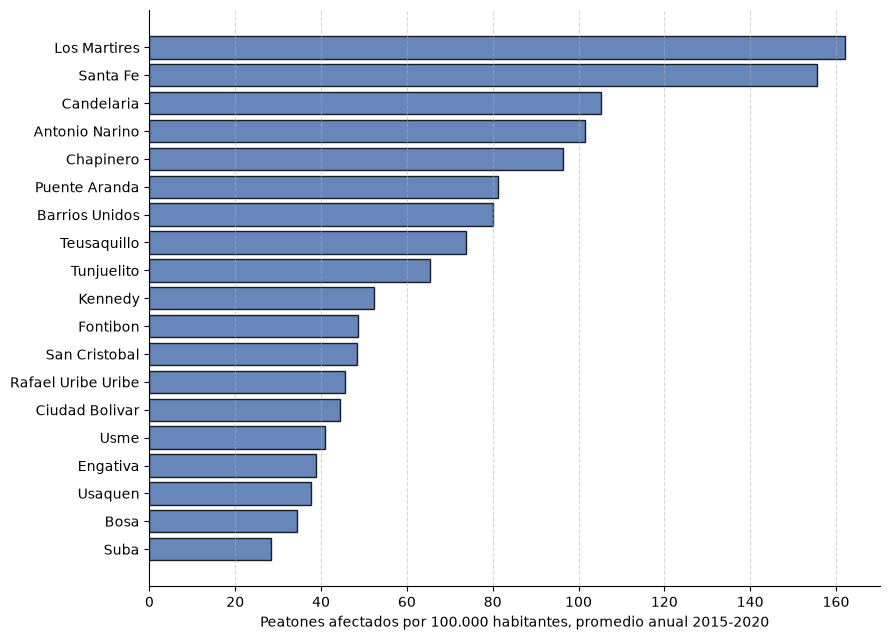

In [23]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    # Tasa ponderada del periodo: casos totales 2015-2020 / población sumada de los 6 años x
    # 100.000. NO es el promedio simple de las 6 tasas anuales (ese promedio sin ponderar fue
    # el que sobreestimó la tasa en versiones anteriores de esta figura).
    per = (
        resumen_localidad_anio.groupby('localidad')
                              .agg(casos=('n_siniestros', 'sum'),
                                   poblacion_suma=('poblacion_total', 'sum'),
                                   n_anios=('anio', 'nunique'))
                              .reset_index()
    )
    per['tasa_periodo'] = per['casos'] / per['poblacion_suma'] * 100_000
    per = per.sort_values('tasa_periodo', ascending=False).reset_index(drop=True)

    N_ANIOS_ESPERADOS = 6  # 2015-2020
    incompletas = per.loc[per['n_anios'] < N_ANIOS_ESPERADOS, ['localidad', 'n_anios']]
    if len(incompletas):
        print("Localidades con menos de 6 años de datos en la tasa (revisar antes de citar):")
        print(incompletas.to_string(index=False))

    print(per[['localidad', 'casos', 'poblacion_suma', 'tasa_periodo']].to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    d = per.sort_values('tasa_periodo')
    ax.barh(d['localidad'].str.title(), d['tasa_periodo'], color='#4C72B0', edgecolor='black', alpha=0.85)
    ax.set_xlabel('Peatones afectados por 100.000 habitantes, promedio anual 2015-2020')
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout(); plt.show()


## 5. Construcción del dataset final por segmento

Una fila = una vía. Las covariables de infraestructura y la variable respuesta —el **conteo
de siniestros por segmento**— vienen todas de una asignación por vecino más próximo, así que
no hace falta distinguir modos de agregación.

In [24]:
def construir_dataset():
    # MVI_VELREG (velocidad reglamentaria) y MVINUMC (número de calzadas) son covariables de
    # diseño vial del modelo: se conservan explícitamente (no por 'if c in columns').
    ds = segmentos[['seg_id', 'vial_id', 'long_seg_m', 'geometry', *COLS_DISENO_VIAL] +
                   [c for c in ['MVITIPO', 'MVISVIA'] if c in segmentos.columns]].copy()

    ds = ds.merge(puentes_agg,        on='seg_id', how='left')
    ds = ds.merge(semaforos_agg,      on='seg_id', how='left')
    ds = ds.merge(peatonal_agg,       on='seg_id', how='left')
    ds = ds.merge(siniestros_agg,     on='seg_id', how='left')
    # Población por localidad asignada directamente a la vía (sección 4.7.1-4.7.3): cubre
    # el 100% de la red, tenga o no siniestros, a diferencia del enfoque vía-siniestros.
    ds = ds.merge(poblacion_segmento, on='seg_id', how='left')

    # Conteos ausentes = ausencia real del fenómeno, no dato faltante
    cols_conteo = [c for c in ds.columns if c.startswith('n_')]
    ds[cols_conteo] = ds[cols_conteo].fillna(0)
    for c in cols_conteo:
        if ds[c].dropna().mod(1).eq(0).all():
            ds[c] = ds[c].astype(int)

    # Cobertura peatonal: peatonal_agg trae una fila por vía y sin NaN (0 = sin cobertura)
    ds['tiene_infra_peatonal'] = ds['ratio_cobertura_peatonal'] > 0

    if 'n_peatones_afectados' in ds.columns:
        ds['tuvo_siniestro'] = ds['n_peatones_afectados'] > 0
    return ds

dataset_final = construir_dataset()

print(f"Dataset final: {dataset_final.shape}")
print(f"% con cobertura peatonal (> 0)           : {dataset_final['tiene_infra_peatonal'].mean()*100:.2f}%")
print(f"Cobertura peatonal media (0-1)           : {dataset_final['ratio_cobertura_peatonal'].mean():.3f}")
print(f"Velocidad reglamentaria / calzadas       : "
      f"{dataset_final['MVI_VELREG'].notna().mean()*100:.1f}% / {dataset_final['MVINUMC'].notna().mean()*100:.1f}% con dato")
print(f"% con siniestro                         : {dataset_final['tuvo_siniestro'].mean()*100:.2f}%")
print(f"Siniestros totales capturados            : {dataset_final['n_peatones_afectados'].sum():,}")
print(f"% con población de localidad asignada    : {dataset_final['poblacion_localidad'].notna().mean()*100:.2f}%")
dataset_final.head()

Dataset final: (131705, 26)
% con cobertura peatonal (> 0)           : 56.31%
Cobertura peatonal media (0-1)           : 0.410
Velocidad reglamentaria / calzadas       : 100.0% / 100.0% con dato
% con siniestro                         : 10.12%
Siniestros totales capturados            : 21,701
% con población de localidad asignada    : 100.00%


,seg_id,vial_id,long_seg_m,geometry,MVI_VELREG,MVINUMC,MVITIPO,MVISVIA,dist_puente_m,dist_puente_peatonal_m,dist_puente_vehicular_m,dist_semaforo_m,ratio_cobertura_peatonal,long_peatonal_m,n_peatones_afectados,n_siniestros,pct_nocturno,n_herido,n_muerto,ano_min,ano_max,localidad,poblacion_localidad,log_poblacion,tiene_infra_peatonal,tuvo_siniestro
0,S0000000,91428,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",30.0,2.0,CL,SD,2149.708556,2149.708556,2248.410504,1410.063301,0.0,0.0,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,615104.5,13.329547,False,False
1,S0000001,103844,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",30.0,2.0,CL,SD,2130.397897,2130.397897,2218.697332,1378.963885,0.0,0.0,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,615104.5,13.329547,False,False
2,S0000002,136273,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",30.0,1.0,DG,SD,2108.777826,2108.777826,2173.881717,1232.553221,0.0,0.0,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,615104.5,13.329547,False,False
3,S0000003,122955,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",30.0,1.0,KR,SD,2102.083822,2102.083822,2208.676848,1410.063301,0.0,0.0,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,615104.5,13.329547,False,False
4,S0000004,106448,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",30.0,1.0,DG,SD,2106.174016,2106.174016,2164.688445,1255.390362,0.0,0.0,0,0,NaN,0,0,NaN,NaN,CIUDAD BOLIVAR,615104.5,13.329547,False,False


### 5.1 Desbalance de la variable respuesta (conteo de siniestros por segmento)

La mayoría de las vías de Bogotá no tuvo ningún siniestro peatonal. Cuantificarlo aquí
justifica las decisiones de modelado (pesos de clase, métricas distintas de exactitud) y
anticipa si conviene un modelo de conteos inflado en ceros.

findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.


Vías sin siniestros : 118,383 (89.88%)
Vías con >=1         : 13,322 (10.12%)
Máximo en una vía    : 54

Distribución de conteos:
n_peatones_afectados
0     118383
1       9116
2       2360
3        936
4        402
5        212
6        113
7         69
8         29
9         22
10        19
11        12
Name: count, dtype: int64


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmti10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


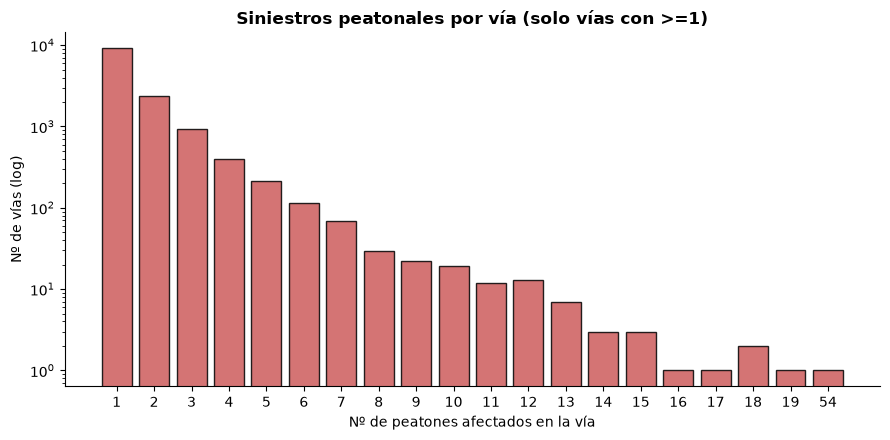

In [25]:
vr = dataset_final['n_peatones_afectados']
print(f"Vías sin siniestros : {(vr == 0).sum():,} ({(vr == 0).mean()*100:.2f}%)")
print(f"Vías con >=1         : {(vr > 0).sum():,} ({(vr > 0).mean()*100:.2f}%)")
print(f"Máximo en una vía    : {vr.max()}")
print(f"\nDistribución de conteos:")
print(vr.value_counts().sort_index().head(12))

fig, ax = plt.subplots(figsize=(9, 4.5))
conteo_vr = vr[vr > 0].value_counts().sort_index()
ax.bar(conteo_vr.index.astype(str), conteo_vr.values,
       color='indianred', edgecolor='black', alpha=0.85)
ax.set_yscale('log')
ax.set_title('Siniestros peatonales por vía (solo vías con >=1)', fontweight='bold')
ax.set_xlabel('Nº de peatones afectados en la vía'); ax.set_ylabel('Nº de vías (log)')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Vista espacial del resultado

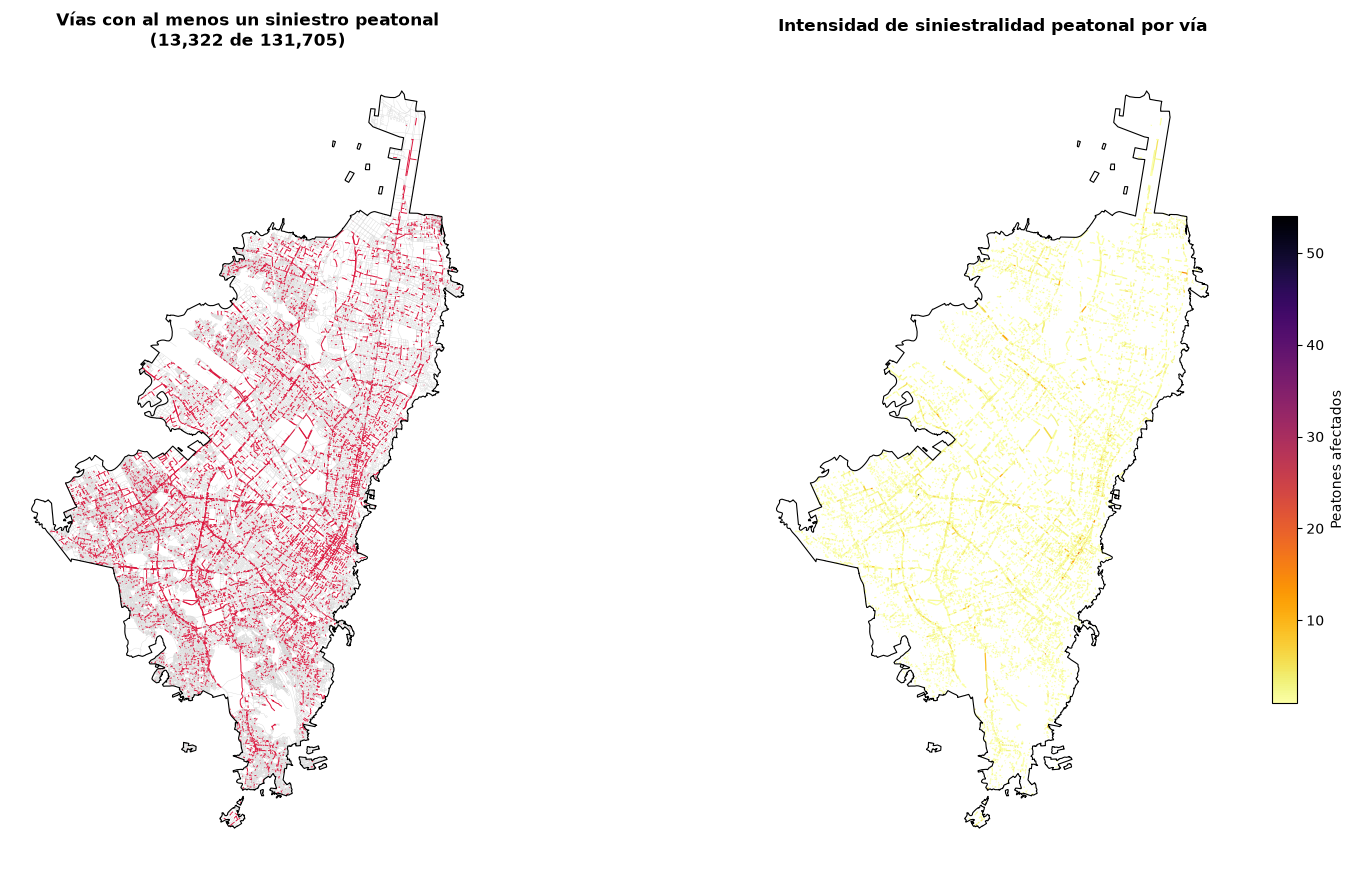

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# Izquierda: red coloreada por presencia de siniestros
sin_sin = dataset_final[~dataset_final['tuvo_siniestro']]
con_sin = dataset_final[dataset_final['tuvo_siniestro']]
sin_sin.plot(ax=axes[0], color='lightgray', linewidth=0.25, zorder=1)
con_sin.plot(ax=axes[0], color='crimson', linewidth=0.7, zorder=2)
perimetro.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
axes[0].set_title(f'Vías con al menos un siniestro peatonal\n'
                  f'({len(con_sin):,} de {len(dataset_final):,})', fontweight='bold')

# Derecha: intensidad
con_sin.plot(ax=axes[1], column='n_peatones_afectados', cmap='inferno_r',
             linewidth=0.9, legend=True, scheme=None,
             legend_kwds={'label': 'Peatones afectados', 'shrink': 0.6})
perimetro.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
axes[1].set_title('Intensidad de siniestralidad peatonal por vía', fontweight='bold')

for ax in axes:
    ax.set_axis_off()
plt.tight_layout(); plt.show()

## 7. Exportación

Se exporta el dataset a nivel de vía.

In [27]:
salida = f'{DIR_PROC}/segmentos_unificado.gpkg'

# Capa principal de análisis
dataset_final.to_file(salida, layer='segmentos', driver='GPKG')

# Versión tabular para modelado (sin geometría)
cols_drop = ['seg_id', 'vial_id', 'geometry', 'MVITIPO', 'MVISVIA', 'localidad',
       'dist_puente_m', 'long_peatonal_m',
       'n_peatones_afectados', 'pct_nocturno', 'ano_min',
       'ano_max', 'tiene_infra_peatonal', 'tuvo_siniestro']
# 'localidad' se descarta como texto (igual que MVITIPO/MVISVIA); 'poblacion_localidad' y
# 'log_poblacion' sí se conservan: son la covariable de exposición poblacional por vía (en
# nivel y en logaritmo — esta última es la que entra al modelo según la Tabla 5).

# Verificación ANTES del fillna(0) de abajo: una vía sin población real no debe convertirse
# en silencio en una vía con población 0 (eso invalidaría log_poblacion, que no admite 0).
n_pob_faltante = dataset_final['poblacion_localidad'].isna().sum()
n_pob_no_positiva = (dataset_final['poblacion_localidad'].fillna(1) <= 0).sum()
assert n_pob_faltante == 0, f"{n_pob_faltante} vías sin población asignada — revisar sección 4.7 antes de exportar"
assert n_pob_no_positiva == 0, f"{n_pob_no_positiva} vías con población <= 0 — revisar sección 4.7 antes de exportar"

# Velocidad y carriles: fillna(0) las convertiría en 'velocidad 0' / '0 calzadas' si hubiera
# algún NaN; llegan imputadas por KNN desde EDA_Malla_Vial, así que no debe haber ninguno.
for c in COLS_DISENO_VIAL:
    assert dataset_final[c].notna().all(), f"{c} tiene {dataset_final[c].isna().sum()} NaN — no exportar"
assert dataset_final['ratio_cobertura_peatonal'].between(0, 1).all()

dataset_final = dataset_final.fillna(0)
dataset_final.drop(columns=cols_drop).to_csv(
    f'{DIR_PROC}/segmentos_unificado.csv', index=False)

# Protección explícita: estas variables NO pueden quedar fuera del CSV de modelado.
csv_cols = pd.read_csv(f'{DIR_PROC}/segmentos_unificado.csv', nrows=0).columns.tolist()
for c in [*COLS_DISENO_VIAL, 'ratio_cobertura_peatonal', 'log_poblacion', 'dist_semaforo_m']:
    assert c in csv_cols, f"{c} no está en el CSV exportado"
print('Columnas del CSV de modelado:', csv_cols)

# Tabla de siniestralidad normalizada por población (anexo de proyecciones), por localidad y año
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio.to_csv(f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv', index=False)

print('GeoPackage:', salida, '| capa: segmentos')
print('CSV       :', f'{DIR_PROC}/segmentos_unificado.csv')
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    print('CSV       :', f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv')
print(f'\nDataset final: {dataset_final.shape[0]:,} vías x {dataset_final.shape[1]} columnas')

Columnas del CSV de modelado: ['long_seg_m', 'MVI_VELREG', 'MVINUMC', 'dist_puente_peatonal_m', 'dist_puente_vehicular_m', 'dist_semaforo_m', 'ratio_cobertura_peatonal', 'n_siniestros', 'n_herido', 'n_muerto', 'poblacion_localidad', 'log_poblacion']
GeoPackage: Data/processed/segmentos_unificado.gpkg | capa: segmentos
CSV       : Data/processed/segmentos_unificado.csv
CSV       : Data/processed/siniestros_tasa_100k_localidad_anio.csv

Dataset final: 131,705 vías x 26 columnas


## 8. Resumen metodológico

**Unidad de análisis.** Cada vía original de la Malla Vial Integral (tras explotar
multipartes y descartar geometrías por debajo de `UMBRAL_RUIDO`) se conserva **completa**, con
su longitud real (`long_seg_m`), en vez de subdividirse en tramos de longitud fija. Esto evita
introducir cortes artificiales; el costo es que la longitud de las vías ahora varía mucho
entre vías cortas y avenidas largas, así que cualquier comparación de conteos crudos entre
vías debería tener en cuenta esa longitud (por ejemplo, usándola como *offset* de exposición
en un modelo de conteos).

**Agregación por vecino más próximo.** 
Cada elemento de las capas de infraestructura y de siniestralidad se asigna a la vía más
cercana mediante `sjoin_nearest`. Puentes y semáforos se resumen como **distancia al más
cercano** (`dist_puente_m`, `dist_semaforo_m`), sin límite de distancia. Los siniestros se
**cuentan** en la vía más cercana dentro de un umbral (`UMBRAL_SINIESTROS_M`), y cada
siniestro pertenece a una única vía. Cuando un
siniestro queda empatado a la misma distancia mínima de dos o más vías —típicamente en una
intersección, donde convergen varias vías—, se conserva la de menor `seg_id`: un criterio sin
sustento sustantivo frente al fenómeno, pero explícito y reproducible (sección 4.6).

**Malla peatonal.** Se resume como un indicador de cobertura, `ratio_cobertura_peatonal` ∈
[0, 1]: proporción de la longitud de la vía con malla peatonal a ≤ `UMBRAL_PEATONAL_M` (15 m),
estimada muestreando puntos a lo largo del eje de la vía (sección 4.4). Reemplaza a
`dist_peatonal_m`, que era ≈ 0 m para casi todas las vías con dato y quedaba en 0 también
para las vías sin malla tras el `fillna(0)`. `long_peatonal_m` (metros de vía cubiertos) se
conserva solo en el GeoPackage.

**Diseño vial.** `MVI_VELREG` (velocidad reglamentaria) y `MVINUMC` (número de calzadas),
imputadas por KNN en `EDA_Malla_Vial_Puentes`, son obligatorias en este cuaderno y se
exportan en el CSV de modelado; si faltan en el insumo, la ejecución se detiene.

**Variable objetivo.** El conteo de siniestros por vía (`n_peatones_afectados`,
`n_siniestros`). Se retiraron del dataset la edad media de las víctimas
(`edad_media_victima`), el conteo de ilesos (`n_ileso`) y la tasa por 100 m
(`siniestros_por_100m`): las dos primeras no aportaban a la definición del objetivo, y la
tercera dejó de tener sentido al no haber ya una comparación entre distintos tamaños de
segmento.

**Integración con proyecciones de población.** Fuente: Población en Bogotá D.C. por
localidad, 2005-2035 (SDS/SaluData, convenio DANE-SDP), que reemplazó al anexo DANE/SDP
2018-2035 usado en una versión anterior. Cubre el periodo de estudio completo (2015-2020) sin
necesidad de excluir ni aproximar años. Solo 2005 y 2018 son censos reales; el resto de los
años (incluidos 2015-2017, 2019 y 2020) son proyecciones o retroproyecciones del DANE/SDP —
si se cita población de un año no censal en el documento, debe declararse esa naturaleza.

La población se incorpora de dos formas independientes, cada una con su propia unidad de
análisis:
- **A cada vía** (`poblacion_localidad` y `log_poblacion`, secciones 4.7.1-4.7.3): por
  posición espacial del centroide de la vía dentro de una localidad (capa SDP de
  localidades), con la población representativa de esa localidad promediada entre 2015 y
  2020 (el periodo de estudio completo). No depende de que la vía tenga siniestros
  asignados, así que cubre el 100% de la red. `log_poblacion` es la covariable que entra al
  modelo (Tabla 5); como solo toma 19 valores distintos para 131.705 vías, su coeficiente
  recoge diferencias ENTRE localidades, no dentro de ellas, y los errores estándar deben
  agruparse por localidad (19 grupos — inferencia frágil con tan pocos grupos, debe
  declararse como limitación).
- **A cada siniestro, por localidad y año exacto** (sección 4.7.4): el cruce exige
  coincidencia exacta de año; un siniestro cuyo año no tuviera población en la fuente se
  excluiría (no se aproximaría con otro año), aunque con la cobertura 2005-2035 esto no
  debería ocurrir dentro de 2015-2020. Se usa en dos tablas: `resumen_localidad_anio`
  (detalle por año, exportada a `siniestros_tasa_100k_localidad_anio.csv`) y `tasa_periodo`
  (una tasa por localidad para todo 2015-2020, la que alimenta la Figura 4), calculada como
  **casos totales ÷ población sumada de los 6 años × 100.000** — la tasa anual promedio
  ponderada por población, no el promedio simple de las 6 tasas anuales (ese promedio sin
  ponderar sobreestimaba la tasa en versiones anteriores de esta figura).

**Puntos a revisar con las salidas reales:**
- El % de cobertura de la sección 4.6 dice si `UMBRAL_SINIESTROS_M` (30 m) es razonable o hay
  que ajustarlo.
- El desbalance de la sección 5.1 condiciona la elección de modelo y métricas — con vías de
  longitud muy variable, probablemente convenga modelar tasas o usar `long_seg_m` como offset
  en vez del conteo crudo directamente.
- La sección 4.7.1 requiere la capa de localidades en `Data/raw/` (no incluida todavía).
- Verificar al correr la celda de carga (4.7) el chequeo de magnitud (población total de
  Bogotá en el año más reciente, debería rondar 7-8 millones) y el mensaje sobre categorías
  de `SEXO`: si el desglose por sexo no se arma, no afecta el total pero conviene saber por qué.
- Declarar en el documento que los años no censales (todos excepto 2005 y 2018) son
  proyecciones o retroproyecciones del DANE/SDP, no mediciones directas.
- **Decisión abierta (sin resolver en este cuaderno):** la tasa de 4.7.4 usa el universo
  georreferenciado de `siniestros` (excluye el 6,63% sin coordenadas). Usar el universo
  completo de actores viales (23.447) evitaría esa subestimación, pero exige cargar aquí una
  fuente que este cuaderno no lee hoy, y debe decidirse junto con el N que usan la Tabla 2,
  la Tabla 4 y la Figura 4 en el documento, para que todos compartan el mismo universo.